# DL_05 — Multitask model, integration and comparison with AML

**Purpose.** Train the full shared-trunk multitask network (building + floor + coordinate heads),
evaluate it once on the held-out partition, and compare it with (a) the three single-task DL
ablations from DL_02–DL_04 and (b) the AML Random Forest baseline from ML_05 — all on the same
1,111 held-out rows with the same metrics.

**Multitask loss.** `L = 1·CE(building) + 1·CE(floor) + 1·Huber((xy − μ_train) / 10)`, weights fixed
a priori. Early stopping monitors the same weighted loss on internal validation.

**Prerequisite.** DL_02–DL_04 checkpoints (`models/dl_0{2,3,4}_*_model.pt`) — committed, or produced
by those notebooks or `python scripts/run_dl_pipeline.py train`.

**Outputs.** `models/dl_05_multitask_model.pt|json`, `data/tables/dl_05_*`, `data/figures/dl_05_*`.

In [1]:
import sys
from pathlib import Path

# Locate the repository root whether Jupyter starts in the root or in "Deep Learning Pipeline/".
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "signal2space_dl").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import json, platform
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

from signal2space_dl import config as C, data as D, evaluate as E, plots as P
from signal2space_dl.cli import run_compare, run_evaluate, run_train

paths = C.Paths(ROOT).ensure()
cfg = C.TrainConfig()
pd.set_option("display.width", 160, "display.max_columns", 30)
print(f"Repository: {ROOT}")
print(f"Python {platform.python_version()} | torch {torch.__version__} | pandas {pd.__version__} | NumPy {np.__version__}")

Repository: /home/user/Signal2Space
Python 3.13.18 | torch 2.15.0+cu132 | pandas 3.0.6 | NumPy 2.5.4


In [2]:
data = D.prepare(paths, coord_scale=cfg.coord_scale, save=False)
missing = [n for n, p in C.EXPERIMENT_PREFIX.items() if n != "multitask" and not (paths.models / f"{p}_model.pt").exists()]
assert not missing, f"Run DL_02-DL_04 (or the CLI train stage) first; missing: {missing}"

## 1. Train (or reuse) the multitask model

In [3]:
CHECKPOINT = paths.models / "dl_05_multitask_model.pt"
RETRAIN = False
if RETRAIN or not CHECKPOINT.exists():
    run_train(data, paths, cfg, ["multitask"])
meta = json.loads((paths.models / "dl_05_multitask_model.json").read_text())
print(json.dumps({k: meta[k] for k in ["tasks", "selected_epoch", "epochs_run", "best_internal_validation_loss",
                                       "n_parameters", "training_seconds", "device", "torch_version"]}, indent=1))
print("Loss weights:", meta["config"]["loss_weights"], "| coord_scale:", meta["config"]["coord_scale"])

{
 "tasks": [
  "building",
  "floor",
  "coordinate"
 ],
 "selected_epoch": 48,
 "epochs_run": 63,
 "best_internal_validation_loss": 0.3779266151993198,
 "n_parameters": 765834,
 "training_seconds": 60.1,
 "device": "cpu",
 "torch_version": "2.15.0+cu132"
}
Loss weights: {'building': 1.0, 'floor': 1.0, 'coordinate': 1.0} | coord_scale: 10.0


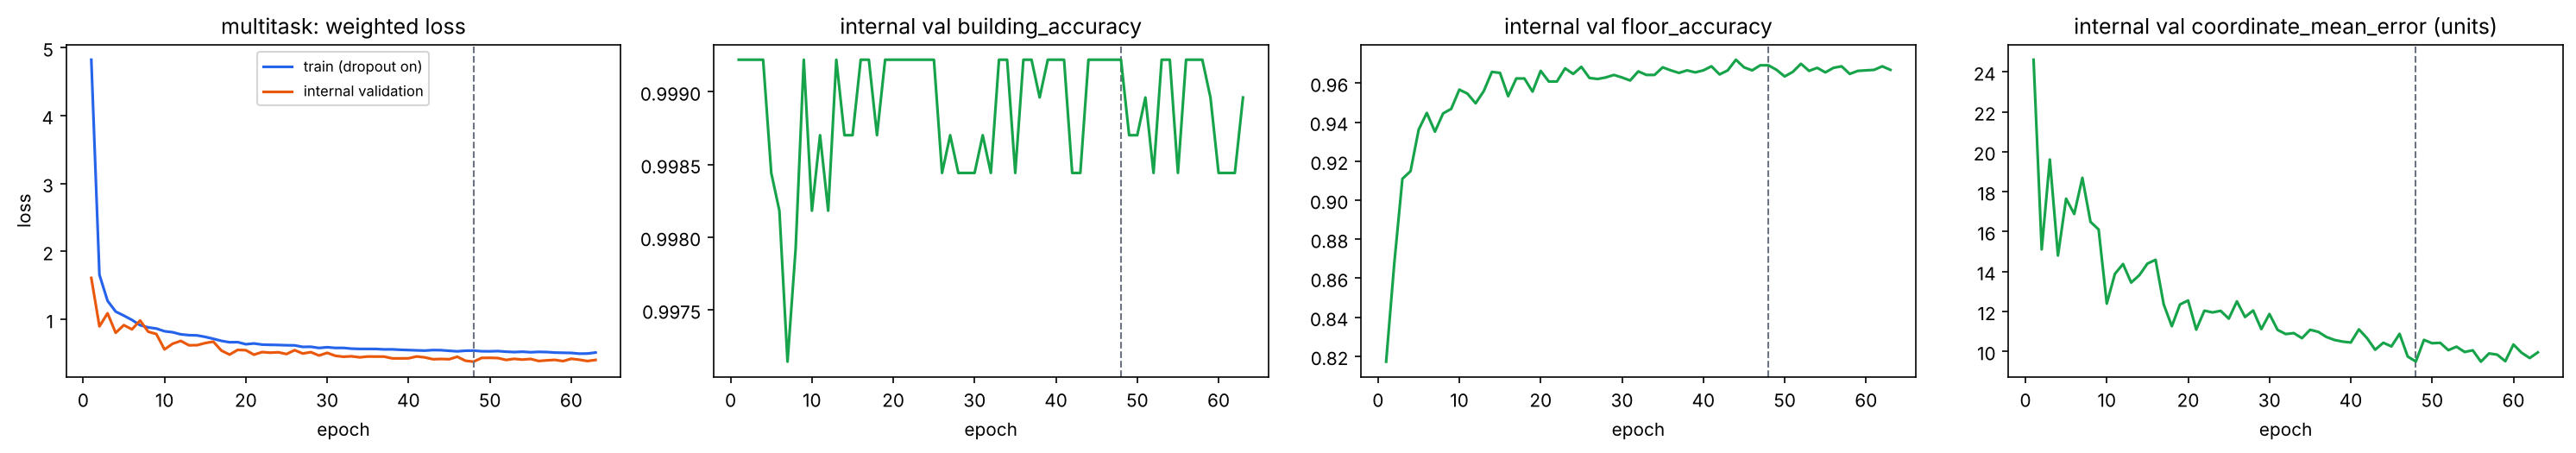

In [4]:
history = pd.read_csv(paths.tables / "dl_05_multitask_training_history.csv")
P.training_curves(history, paths, "dl_05_multitask", "multitask")
display(Image(paths.figures / "dl_05_multitask_training_curves.png"))

## 2. Evaluate all frozen DL models and integrate with AML

In [5]:
preds, rows = run_evaluate(data, paths, list(C.EXPERIMENTS))
summary = run_compare(preds, rows, paths)
table = pd.read_csv(paths.tables / "dl_05_model_comparison.csv")
cols = ["model", "task", "accuracy", "macro_f1", "mae_longitude", "mae_latitude", "mean_euclidean_error",
        "median_euclidean_error", "p90_euclidean_error"]
print("Internal validation (used for early stopping only):")
display(table[table.split == "internal_validation"][cols].round(4))
print("Held-out validationData.csv (1,111 rows, scored once after freezing):")
display(table[table.split == "heldout_validation"][cols].round(4))

Internal validation (used for early stopping only):


,model,task,accuracy,macro_f1,mae_longitude,mae_latitude,mean_euclidean_error,median_euclidean_error,p90_euclidean_error
9,AML Random Forest,building,0.9995,0.9995,NaN,NaN,NaN,NaN,NaN
10,DL building_only,building,0.9992,0.9992,NaN,NaN,NaN,NaN,NaN
11,DL multitask,building,0.9992,0.9992,NaN,NaN,NaN,NaN,NaN
12,AML Random Forest,coordinate,NaN,NaN,5.9142,5.0607,8.5786,6.3067,17.3765
13,DL coordinate_only,coordinate,NaN,NaN,6.0487,4.7078,8.4456,6.7890,15.9293
14,DL multitask,coordinate,NaN,NaN,7.1657,4.8756,9.4924,7.8382,17.5816
15,AML Random Forest,floor,0.9642,0.9678,NaN,NaN,NaN,NaN,NaN
16,DL floor_only,floor,0.9738,0.9750,NaN,NaN,NaN,NaN,NaN
17,DL multitask,floor,0.9691,0.9709,NaN,NaN,NaN,NaN,NaN


Held-out validationData.csv (1,111 rows, scored once after freezing):


,model,task,accuracy,macro_f1,mae_longitude,mae_latitude,mean_euclidean_error,median_euclidean_error,p90_euclidean_error
0,AML Random Forest,building,0.9973,0.9971,NaN,NaN,NaN,NaN,NaN
1,DL building_only,building,0.9982,0.9983,NaN,NaN,NaN,NaN,NaN
2,DL multitask,building,0.9991,0.9988,NaN,NaN,NaN,NaN,NaN
3,AML Random Forest,coordinate,NaN,NaN,8.0966,6.8064,11.5836,7.4884,24.3892
4,DL coordinate_only,coordinate,NaN,NaN,7.2448,6.1074,10.5066,8.1348,21.3471
5,DL multitask,coordinate,NaN,NaN,8.6176,6.7189,12.0015,9.5286,23.7059
6,AML Random Forest,floor,0.8893,0.8727,NaN,NaN,NaN,NaN,NaN
7,DL floor_only,floor,0.8992,0.8843,NaN,NaN,NaN,NaN,NaN
8,DL multitask,floor,0.8956,0.8815,NaN,NaN,NaN,NaN,NaN


In [6]:
print("AML metrics recomputed from its row-level predictions:", summary.get("aml_recomputed"))
print("DL multitask joint building+floor correct:", summary["dl_multitask_joint_building_floor_correct"], "/ 1111")
display(pd.read_csv(paths.tables / "dl_05_vs_aml_paired_bootstrap.csv").round(4))

AML metrics recomputed from its row-level predictions: {'building_accuracy': 0.9972997299729973, 'floor_accuracy': 0.8892889288928892, 'mean_euclidean_error': 11.58357067768045, 'joint_building_floor_correct': 986}
DL multitask joint building+floor correct: 995 / 1111


,model,metric,dl,aml,dl_minus_aml,ci95_low,ci95_high,n_rows,n_bootstrap
0,DL building_only,building_accuracy,0.9982,0.9973,0.0009,-0.0018,0.0036,1111,2000
1,DL floor_only,floor_accuracy,0.8992,0.8893,0.0099,-0.0036,0.0243,1111,2000
2,DL coordinate_only,mean_euclidean_error,10.5066,11.5836,-1.0770,-1.7850,-0.3704,1111,2000
3,DL multitask,building_accuracy,0.9991,0.9973,0.0018,-0.0018,0.0054,1111,2000
4,DL multitask,floor_accuracy,0.8956,0.8893,0.0063,-0.0072,0.0189,1111,2000
5,DL multitask,mean_euclidean_error,12.0015,11.5836,0.4179,-0.3313,1.1638,1111,2000


The paired bootstrap resamples the identical 1,111 held-out rows and reports DL minus AML.
It describes sampling uncertainty over these rows only; it does not account for the
partition's design limits (see Limitations).

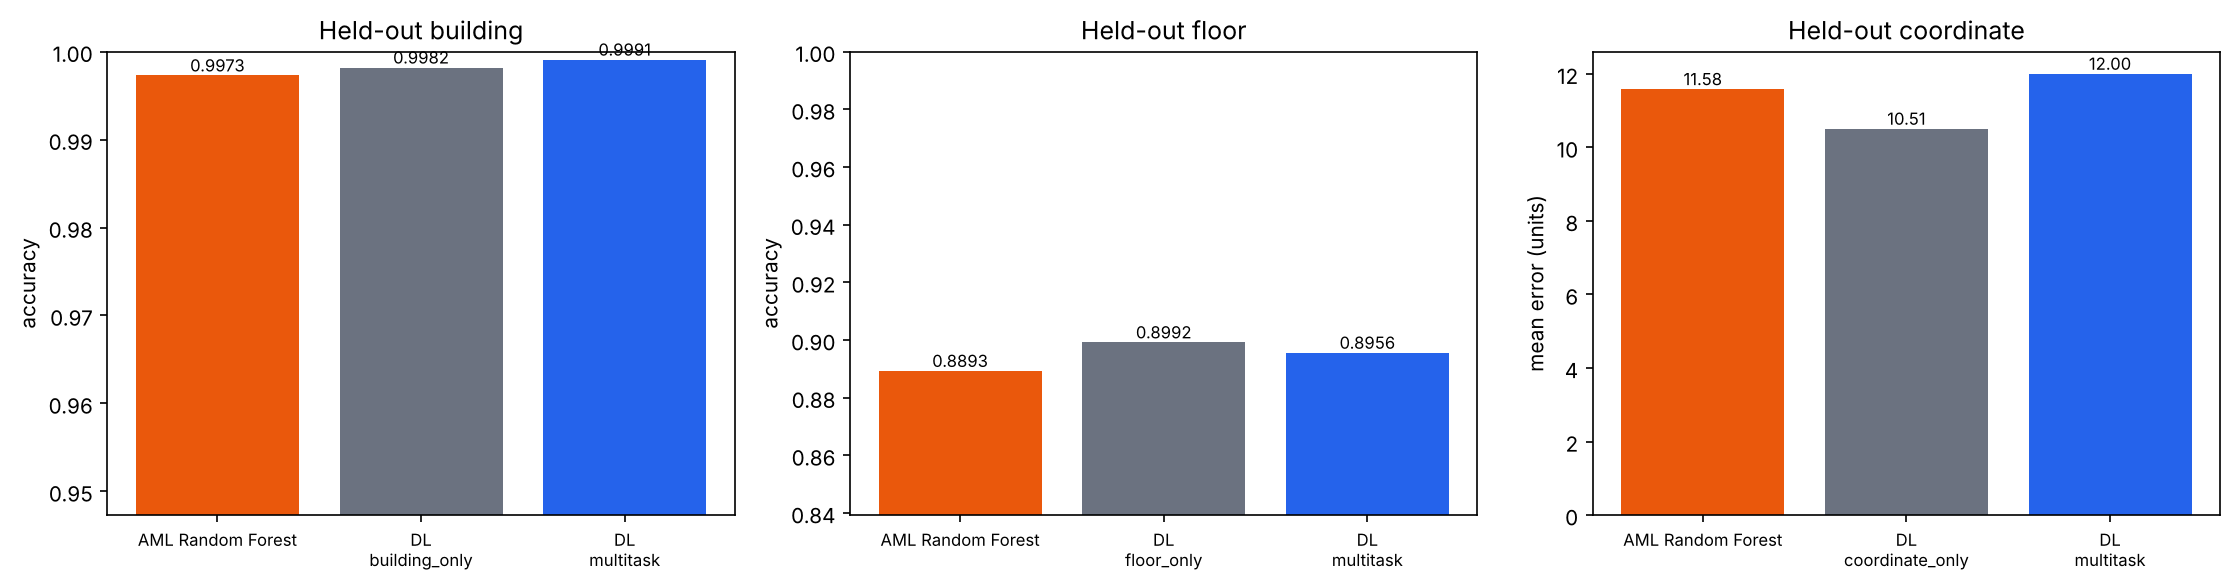

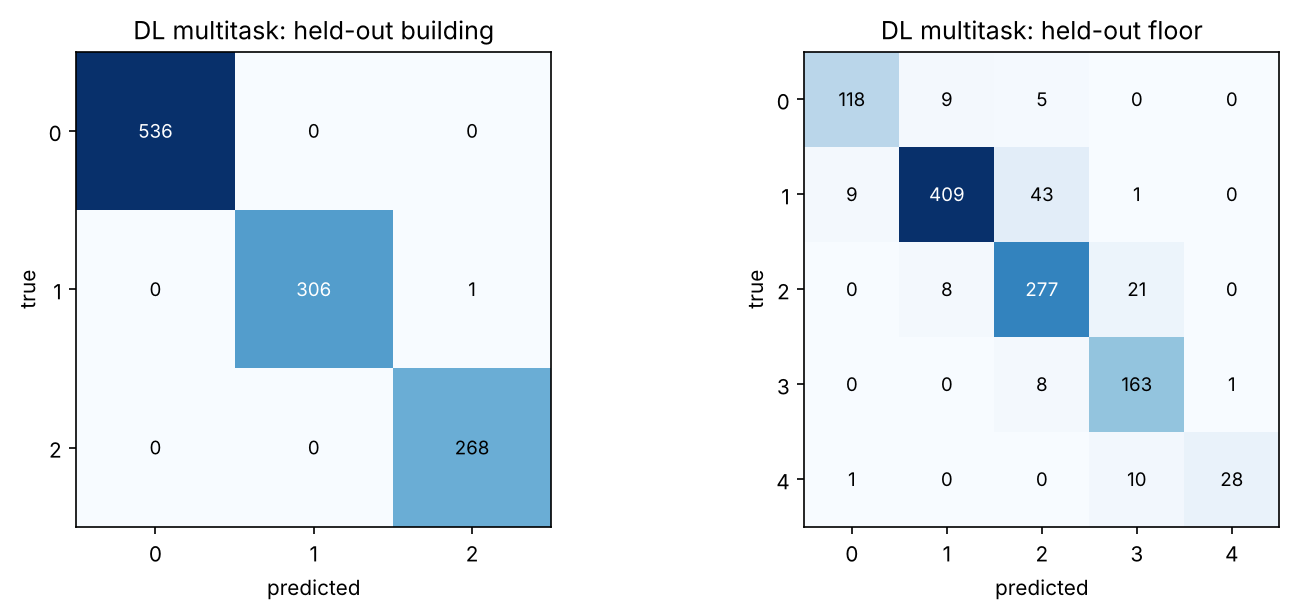

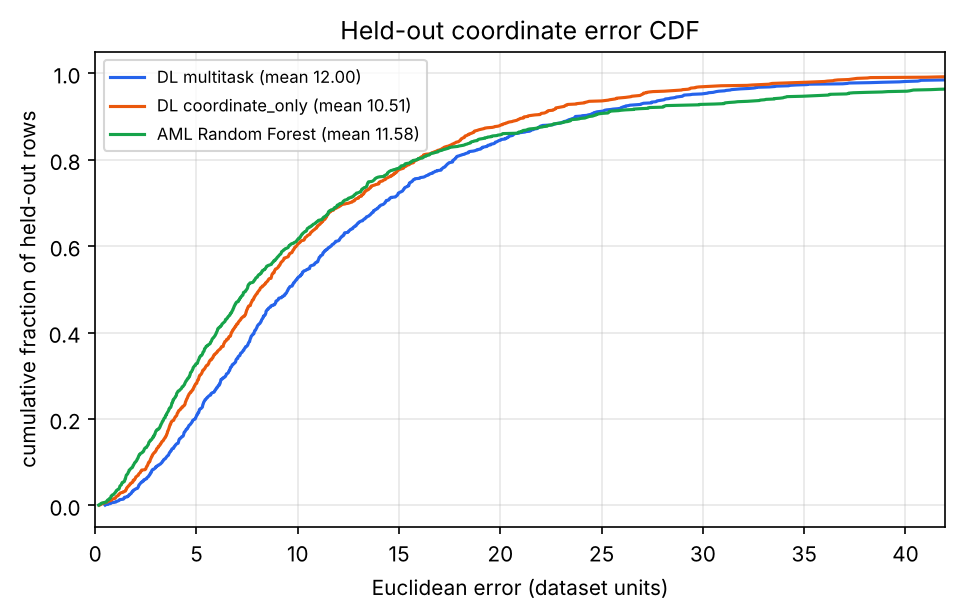

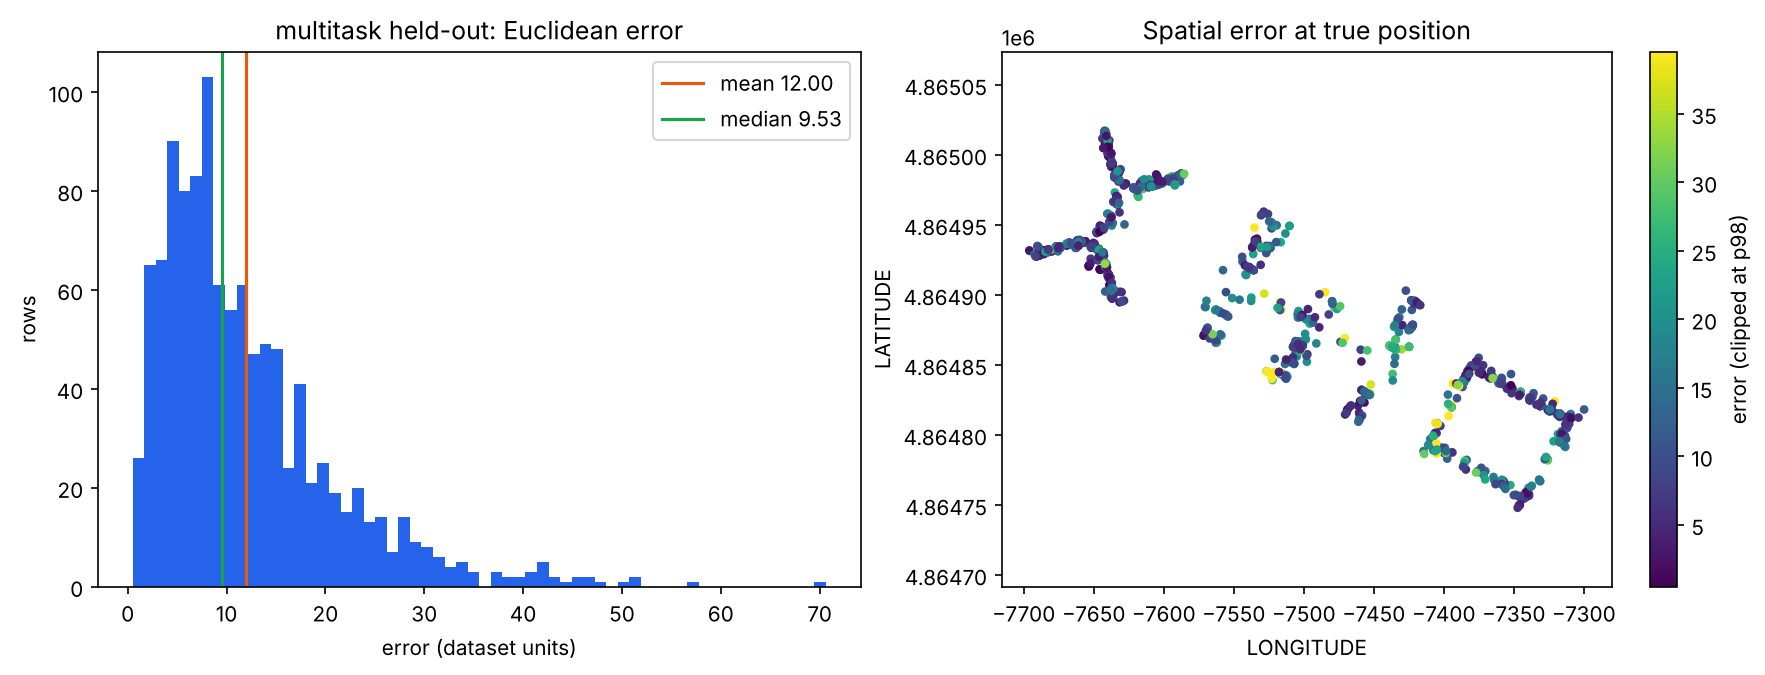

In [7]:
display(Image(paths.figures / "dl_05_heldout_model_comparison.png"))
display(Image(paths.figures / "dl_05_multitask_heldout_confusion_matrices.png"))
display(Image(paths.figures / "dl_05_heldout_error_cdf.png"))
display(Image(paths.figures / "dl_05_multitask_coordinate_errors.png"))

## 3. Hierarchical consistency and per-building error

In [8]:
display(pd.read_csv(paths.tables / "dl_05_hierarchical_breakdown.csv").round(4))
display(pd.read_csv(paths.tables / "dl_05_heldout_coordinate_error_by_building.csv").round(3))
display(pd.read_csv(paths.tables / "dl_05_multitask_floor_heldout_per_class.csv").round(4))

,model,split,hierarchy_outcome,n_rows,proportion,mean_coordinate_error,median_coordinate_error
0,DL multitask,internal_validation,both_correct,3733,0.9691,9.2342,7.7098
1,DL multitask,internal_validation,building_correct_floor_wrong,116,0.0301,14.0093,11.6915
2,DL multitask,internal_validation,building_wrong_floor_correct,0,0.0000,NaN,NaN
3,DL multitask,internal_validation,both_wrong,3,0.0008,156.0751,165.8785
4,DL multitask,heldout_validation,both_correct,995,0.8956,11.1095,8.9188
5,DL multitask,heldout_validation,building_correct_floor_wrong,115,0.1035,19.6574,17.8466
6,DL multitask,heldout_validation,building_wrong_floor_correct,0,0.0000,NaN,NaN
7,DL multitask,heldout_validation,both_wrong,1,0.0009,19.1201,19.1201
8,AML Random Forest,heldout_validation,both_correct,986,0.8875,10.0048,6.9364
9,AML Random Forest,heldout_validation,building_correct_floor_wrong,122,0.1098,23.2704,15.1930


,model,building,n_rows,mean_euclidean_error,median_euclidean_error
0,DL multitask,0,536,10.276,8.316
1,DL multitask,1,307,14.527,12.320
2,DL multitask,2,268,12.560,9.633


,model,task,class,support,precision,recall,f1
0,DL multitask,floor,0,132,0.9219,0.8939,0.9077
1,DL multitask,floor,1,462,0.9601,0.8853,0.9212
2,DL multitask,floor,2,306,0.8318,0.9052,0.8670
3,DL multitask,floor,3,172,0.8359,0.9477,0.8883
4,DL multitask,floor,4,39,0.9655,0.7179,0.8235


## Findings

- **Multitask (selected at epoch 48 of 63, 765,834 parameters), held-out:** building 99.91% (1,110/1,111), floor 89.56%, coordinate mean error 12.00 (median 9.53). Joint building and floor are correct on **995/1,111** rows, against 986 for AML.
- **Against AML** (paired bootstrap, 95% CI): building +0.18 pp [-0.18, +0.54]; floor +0.63 pp [-0.72, +1.89]; mean coordinate error +0.42 [-0.33, +1.16]. None of these differences is resolved on this split.
- **Against the single-task ablations:** sharing one trunk helped building slightly, cost a little floor accuracy (89.56% vs 89.92%) and clearly cost coordinate accuracy (12.00 vs 10.51 mean error). On these settings, the coordinate head competes with the classification heads for trunk capacity.
- **Recommendation:** use the multitask model as the single deployable network (one forward pass, consistent outputs). The best-performing DL configuration per task is building from multitask, floor from floor_only and coordinates from coordinate_only.
- **Not used to choose models:** these held-out comparisons were computed after all checkpoints were frozen and were not used to pick any of them. Choosing a per-task combination now would be a post-hoc decision, so it is reported as an observation, not a tuned result. The next step is to tune the coordinate loss weight or `coord_scale` on internal validation only.

## Limitations

- **Coordinate units/CRS.** Values look like Web-Mercator metres and ML_04 labels them EPSG:3857, but the
  repository has no authoritative CRS metadata. Errors are therefore reported in dataset units.
  Web-Mercator distances are also inflated by about 1/cos(latitude) relative to ground distance.
- **Supplied split.** `validationData.csv` was collected later with different users/phones, which is
  a useful shift, but it does not guarantee unseen locations; results do not establish performance on
  unseen buildings, unseen positions or new devices in general.
- **Class imbalance.** Floor 4 exists only in building 2 and is the smallest class; macro F1 and per-class
  recall are reported alongside accuracy. Class weighting is implemented (`TrainConfig.class_weighting`)
  but off by default and was not used in the reported run.
- **No hyperparameter search.** Hyperparameters were fixed a priori; only early stopping uses internal
  validation. A search on internal validation could change the conclusions.
- **Single seed.** Results are from seed 42. CPU/GPU/MPS kernels can differ slightly across machines.